# CXC103

In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
import matplotlib.pyplot as plt
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))
 
module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils.ds_helper import get_dataset_distribution
from src.utils.confusion_matrix import generate_confusion
from src.utils.roc_curve import generate_roc_curve
from src.utils.training_plots import plot_train_accuracy, plot_train_loss


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Load dataset 

In [9]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC103"

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [4]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-05-23 20:45:32.378848: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-05-23 20:45:32.378879: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-23 20:45:32.378889: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-23 20:45:32.379663: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-23 20:45:32.379679: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [6]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])

2026-05-21 19:01:39.681960: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


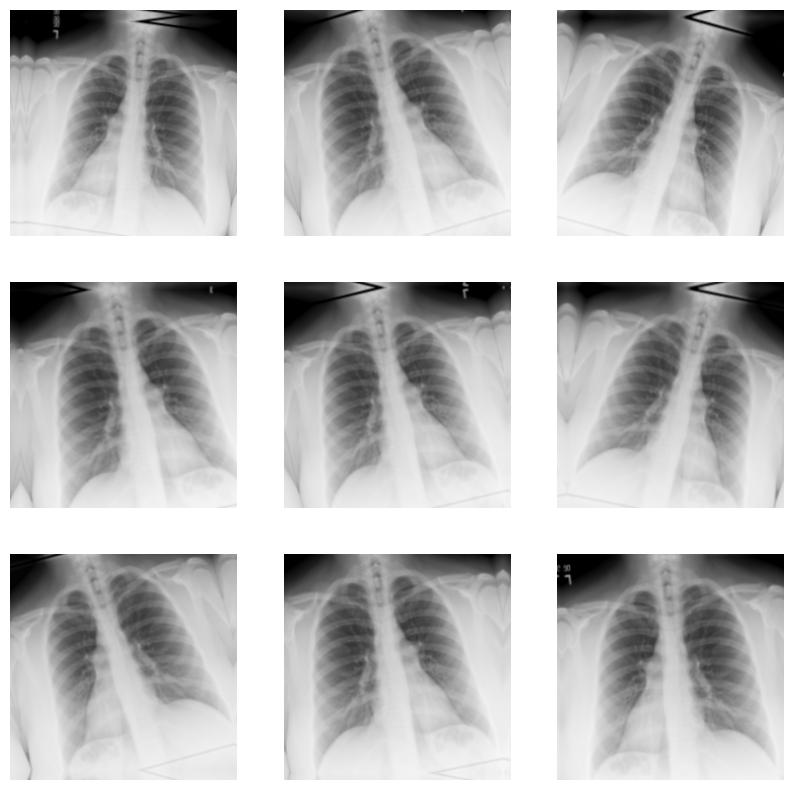

In [9]:
for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

### CNN model Architecture

In [11]:
model = models.Sequential([
    data_augmentation,
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(192, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [30]:
import keras

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# tensorboard_callback = tf.keras.callbacks.TensorBoard(

# tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_folder, histogram_freq=1)


In [ ]:
# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10,
    # callbacks=[tensorboard_callback]
)

Epoch 1/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 173s 277ms/step - accuracy: 0.8865 - loss: 0.3522 - val_accuracy: 0.8699 - val_loss: 0.3692
Epoch 2/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 166s 274ms/step - accuracy: 0.9299 - loss: 0.2037 - val_accuracy: 0.9540 - val_loss: 0.1312
Epoch 3/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 164s 271ms/step - accuracy: 0.9467 - loss: 0.1582 - val_accuracy: 0.9501 - val_loss: 0.1728
Epoch 4/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 163s 270ms/step - accuracy: 0.9571 - loss: 0.1276 - val_accuracy: 0.9619 - val_loss: 0.1198
Epoch 5/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 165s 273ms/step - accuracy: 0.9636 - loss: 0.1056 - val_accuracy: 0.9658 - val_loss: 0.1199
Epoch 6/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 167s 276ms/step - accuracy: 0.9713 - loss: 0.0855 - val_accuracy: 0.8712 - val_loss: 0.3606
Epoch 7/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 162s 267ms/step - accuracy: 0.9757 - loss: 0.0743 - val_accuracy: 0.9343 - val_loss: 0.2170
Epoch 8/10
604/604 ━━━━━━━━━━━━━━━━━━━━ 169s 278ms/step - accuracy: 0.9817 -

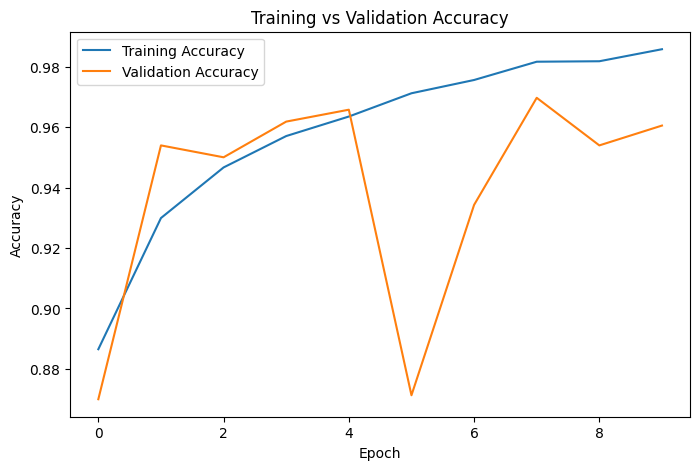

In [34]:
plot_train_accuracy(history=history)

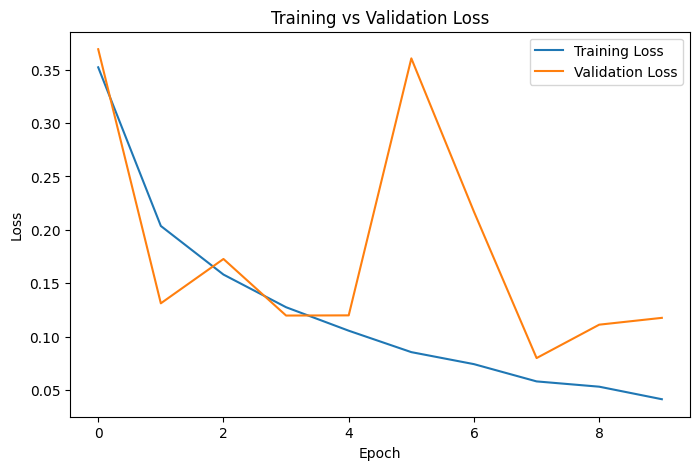

In [35]:
plot_train_loss(history=history)

In [36]:
# Save the model
model.save('CXC1022.keras')
print("Model saved successfully!")

Model saved successfully!


In [11]:
model = tf.keras.models.load_model(os.path.join(model_path, MODEL_NAME+".keras"))

In [12]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 192)    │       110,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 52, 52, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 129792)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    16,613,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,235,918 (191.63 MB)

 Trainable params: 16,745,028 (63.88 MB)

 Non-trainable params: 832 (3.25 KB)

 Optimizer params: 33,490,058 (127.75 MB)

In [18]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.9607 - loss: 0.0999
Test Loss: 0.09993580728769302
Test Accuracy: 96.07%


In [19]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.9606 - loss: 0.1176
Test Loss: 0.1176164373755455
Test Accuracy: 96.06%


2026-05-21 20:12:31.463399: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


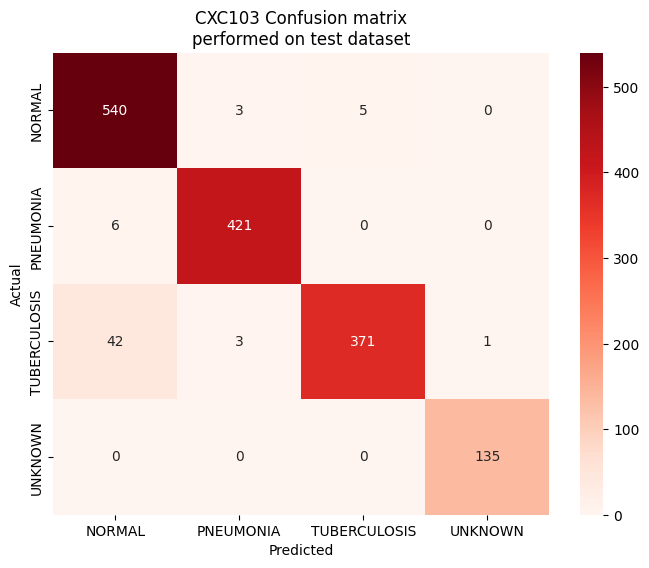

              precision    recall  f1-score   support

      NORMAL       0.92      0.99      0.95       548
   PNEUMONIA       0.99      0.99      0.99       427
TUBERCULOSIS       0.99      0.89      0.94       417
     UNKNOWN       0.99      1.00      1.00       135

    accuracy                           0.96      1527
   macro avg       0.97      0.97      0.97      1527
weighted avg       0.96      0.96      0.96      1527



In [20]:
generate_confusion(
    test_ds, 
    model= model, 
    title= "CXC103 Confusion matrix", 
    subtitle= "performed on test dataset"
)

2026-05-21 20:12:36.350520: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


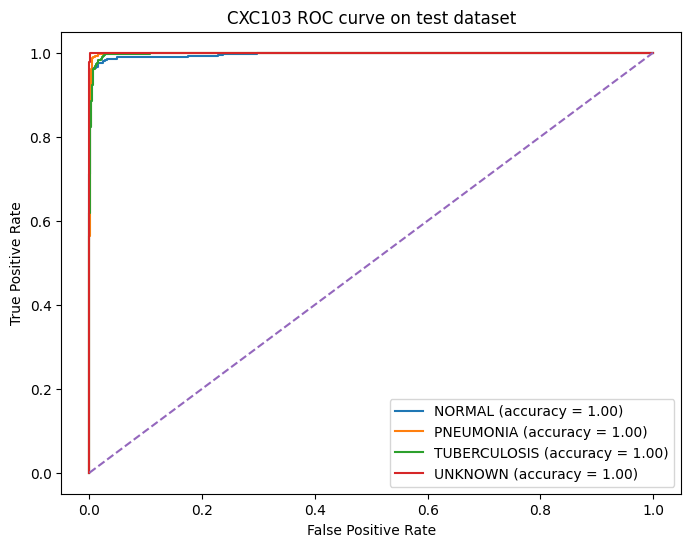

In [21]:
generate_roc_curve(
    test_ds,
    model=model, 
    title="CXC103 ROC curve on test dataset"
    )

2026-05-21 20:12:38.952555: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


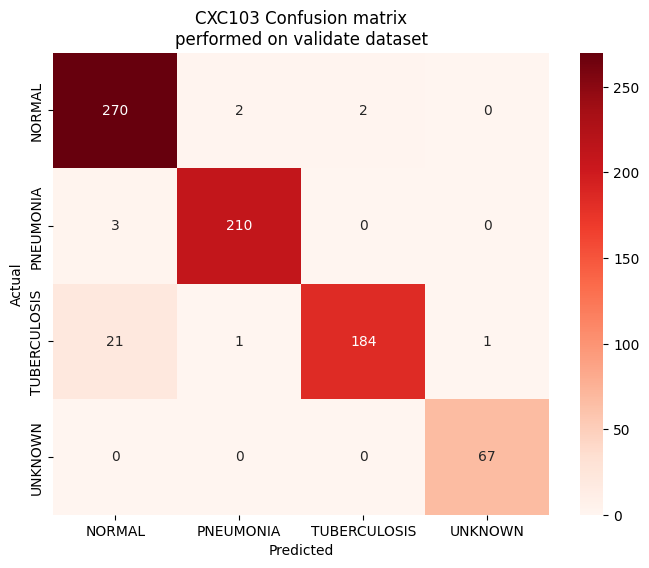

              precision    recall  f1-score   support

      NORMAL       0.92      0.99      0.95       274
   PNEUMONIA       0.99      0.99      0.99       213
TUBERCULOSIS       0.99      0.89      0.94       207
     UNKNOWN       0.99      1.00      0.99        67

    accuracy                           0.96       761
   macro avg       0.97      0.97      0.97       761
weighted avg       0.96      0.96      0.96       761



In [22]:
generate_confusion(
    val_ds, 
    model= model, 
    title= "CXC103 Confusion matrix", 
    subtitle= "performed on validate dataset"
)

2026-05-21 20:12:41.437519: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


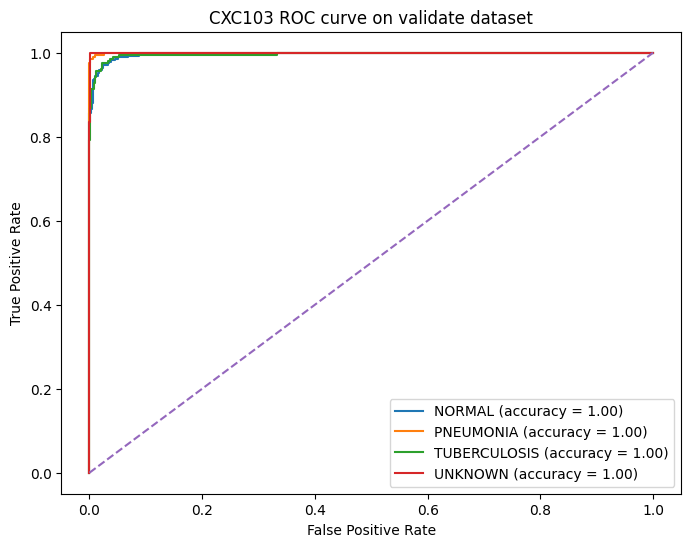

In [23]:
generate_roc_curve(
    val_ds,
    model=model, 
    title="CXC103 ROC curve on validate dataset"
    )